# FCC-ee Z (LCC 108, beam 1): equilibrium vertical emittance with final-doublet motion, VSEI OFF and ON

Questions:
1. Without any vertical errors, what is the equilibrium vertical emittance? (VSEI bends OFF and ON)
2. With a 15 nm RMS vertical displacement of all final doublets, what is the closed orbit and the change in equilibrium emittance?
3. What are the amplification factors?

**Setup** (`run_emittance.py`)
* Beam-1 lattice, radiation model `mean`, energy loss compensated by the cavity on the nominal lattice (the RF is kept fixed when the doublets move), equilibrium emittances from the 6D Twiss with `radiation_analysis`.
* VSEI OFF: `kvsei1 = 0` (the 16 vertical bends `vsei1/2` are switched off). VSEI ON: lattice value, 0.388 mrad.
* Motion: the 16 rigid cryostats (QF1a-d and QD0a-c of each side of each IP) move with $d_g=\sqrt2\,A\cos(\theta+\varphi_g)$, $A$ = 15 nm RMS, random phase per cryostat. 40 random-phase sets (seeds 42-81) x 5 temporal phases.
* Orbit amplification $\kappa_{\rm orbit}$ = RMS of the vertical closed orbit change over all Twiss points / RMS of the applied displacements.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({'font.family': 'serif', 'mathtext.fontset': 'stix', 'font.size': 13, 'axes.labelsize': 14,
    'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True,
    'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight'})
RESULTS = Path('results/emittance'); FIGURES = Path('results/figures'); FIGURES.mkdir(parents=True, exist_ok=True)
A_NM = 15.0
nominal = pd.read_csv(RESULTS/'nominal_emittance.csv').set_index('state')
runs = pd.read_csv(RESULTS/f'emittance_scan_{A_NM:g}nm.csv')
print('converged fraction:', runs.converged.mean()); runs = runs[runs.converged].copy()

converged fraction: 1.0


## 1. Initial equilibrium emittance (no errors)

In [2]:
table = pd.DataFrame({'eps_x [nm]': 1e9*nominal.eq_gemitt_x_m, 'eps_y [pm]': 1e12*nominal.eq_gemitt_y_m, 'eps_y [fm]': 1e15*nominal.eq_gemitt_y_m,
                      'eps_y/eps_x': nominal.eq_gemitt_y_m/nominal.eq_gemitt_x_m})
table.index = ['VSEI ' + s.upper() for s in table.index]
display(table)

,eps_x [nm],eps_y [pm],eps_y [fm],eps_y/eps_x
VSEI OFF,1.215826,9.383695e-38,9.383695e-35,7.717961e-41
VSEI ON,1.214945,4.785998e-03,4.785998e+00,3.939272e-06


## 2. Orbit and emittance with 15 nm RMS motion of all final doublets

In [3]:
EY0 = {s: nominal.loc[s, 'eq_gemitt_y_m'] for s in ('off', 'on')}
runs['kappa_orbit'] = runs.orbit_y_rms_um*1e-6/(runs.input_rms_nm*1e-9)
runs['eps_y_pm'] = 1e12*runs.eq_gemitt_y_m
runs['delta_eps_y_pm'] = runs.eps_y_pm - runs.state.map(lambda s: 1e12*EY0[s])
# average over the 5 temporal phases for each seed, as in the seed studies
per_seed = runs.groupby(['state', 'seed']).agg(eps_y_pm=('eps_y_pm', 'mean'), orbit_rms_um=('orbit_y_rms_um', 'mean'),
        orbit_max_um=('orbit_y_max_um', 'max'), kappa_orbit=('kappa_orbit', 'mean'), ddy_rms_mm=('delta_dy_rms_mm', 'mean'),
        input_rms_nm=('input_rms_nm', 'mean'), **{f'{ip}_peak_offset_nm': (f'{ip}_offset_nm', lambda v: np.max(np.abs(v))) for ip in ('ipa', 'ipd', 'ipg', 'ipj')}).reset_index()
per_seed.to_csv(RESULTS/f'per_seed_summary_{A_NM:g}nm.csv', index=False)
rows = []
for state in ('off', 'on'):
    d = per_seed[per_seed.state == state]
    rows.append({'VSEI': state.upper(), 'eps_y initial [pm]': 1e12*EY0[state],
        'eps_y with motion, median [pm]': d.eps_y_pm.median(), 'mean [pm]': d.eps_y_pm.mean(), '16%': d.eps_y_pm.quantile(0.16), '84%': d.eps_y_pm.quantile(0.84), '95%': d.eps_y_pm.quantile(0.95),
        'orbit RMS, median [um]': d.orbit_rms_um.median(), 'orbit max, median [um]': d.orbit_max_um.median(),
        'kappa_orbit, median': d.kappa_orbit.median(), 'delta dy RMS, median [mm]': d.ddy_rms_mm.median()})
summary = pd.DataFrame(rows).set_index('VSEI'); summary.to_csv(RESULTS/f'summary_{A_NM:g}nm.csv')
display(summary.T.round(4))

VSEI,OFF,ON
eps_y initial [pm],0.0000,0.0048
"eps_y with motion, median [pm]",0.1886,0.1932
mean [pm],0.2421,0.2466
16%,0.0469,0.0516
84%,0.4359,0.4402
95%,0.5849,0.5891
"orbit RMS, median [um]",22.9408,22.9408
"orbit max, median [um]",291.3952,291.3950
"kappa_orbit, median",1536.1109,1536.1098
"delta dy RMS, median [mm]",2.3710,2.3709


In [4]:
off = per_seed[per_seed.state == 'off'].set_index('seed'); on = per_seed[per_seed.state == 'on'].set_index('seed')
eps0_on_pm = 1e12*EY0['on']
amp = pd.DataFrame({'eps_y(on) - eps_y(off) [pm], median': [(on.eps_y_pm - off.eps_y_pm).median()],
                    'same, max over seeds': [(on.eps_y_pm - off.eps_y_pm).abs().max()],
                    'eps_y(on, motion) / eps_y(on, initial), median': [on.eps_y_pm.median()/eps0_on_pm],
                    'eps_y(off, motion) per nm^2 of A^2 [fm/nm^2], median': [1e3*off.eps_y_pm.median()/A_NM**2]})
display(amp.T.rename(columns={0: 'value'}))

,value
"eps_y(on) - eps_y(off) [pm], median",0.004544
"same, max over seeds",0.004801
"eps_y(on, motion) / eps_y(on, initial), median",40.361363
"eps_y(off, motion) per nm^2 of A^2 [fm/nm^2], median",0.838337


### Vertical closed orbit, seed 42, temporal phase 0, VSEI OFF and ON

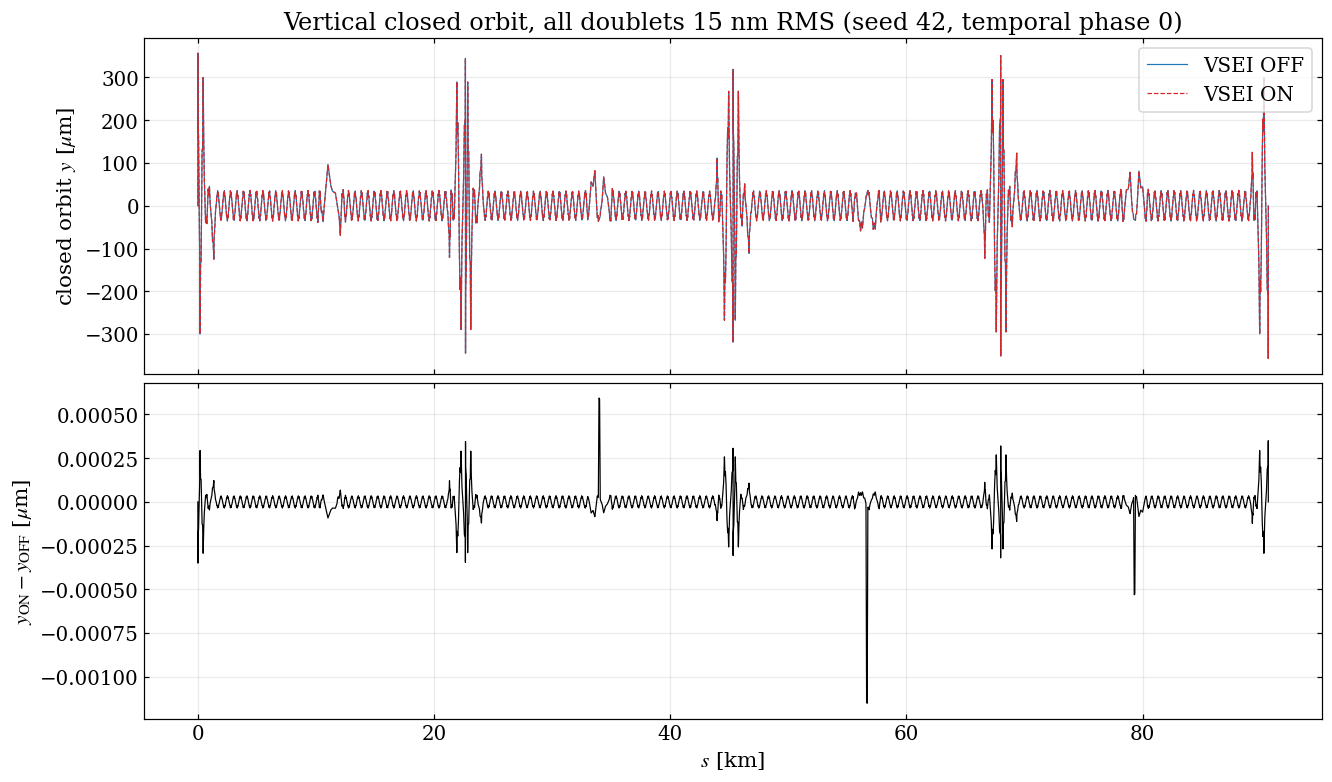

In [5]:
orbit = np.load(RESULTS/f'orbit_seed42_theta0_{A_NM:g}nm.npz')
fig, axes = plt.subplots(2, 1, figsize=(12, 7), layout='constrained', sharex=True)
for state, color, ls in (('off', 'tab:blue', '-'), ('on', 'tab:red', '--')):
    axes[0].plot(orbit[f'{state}_s']/1e3, orbit[f'{state}_y_um'], color=color, ls=ls, lw=0.8, label=f'VSEI {state.upper()}')
axes[0].set_ylabel(r'closed orbit $y$ [$\mu$m]'); axes[0].legend(); axes[0].grid(alpha=0.25)
axes[0].set_title(f'Vertical closed orbit, all doublets {A_NM:g} nm RMS (seed 42, temporal phase 0)')
axes[1].plot(orbit['on_s']/1e3, orbit['on_y_um'] - orbit['off_y_um'], 'k', lw=0.8)
axes[1].set_ylabel(r'$y_{\rm ON}-y_{\rm OFF}$ [$\mu$m]'); axes[1].set_xlabel(r'$s$ [km]'); axes[1].grid(alpha=0.25)
fig.savefig(FIGURES/'emittance_orbit_vsei_on_off.png'); plt.show()

### Distribution of the equilibrium vertical emittance over the random-phase sets

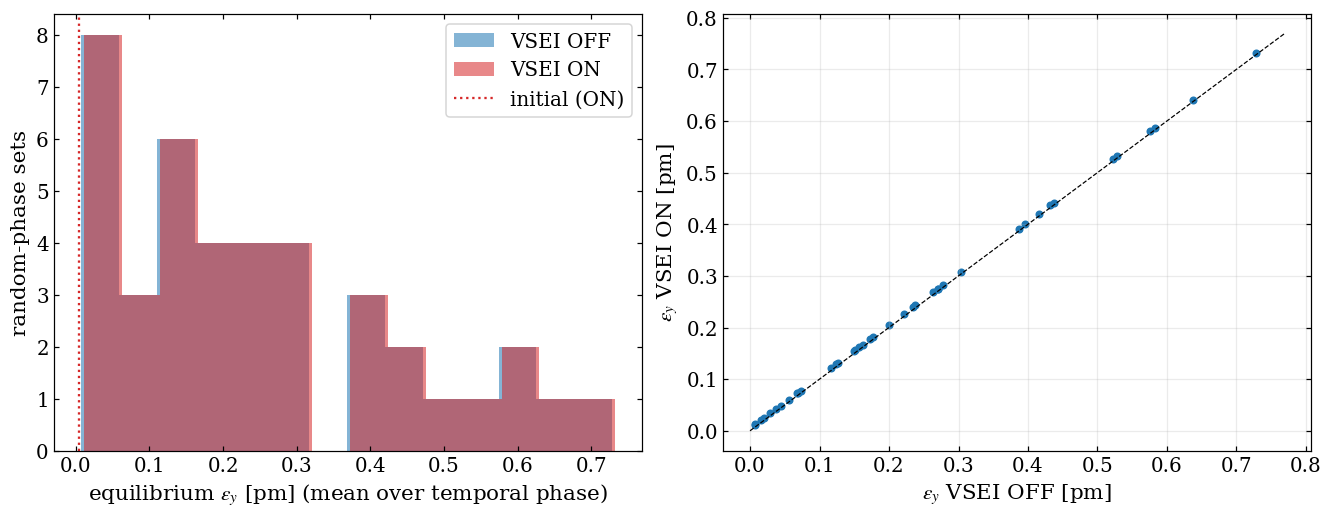

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout='constrained')
for state, color in (('off', 'tab:blue'), ('on', 'tab:red')):
    axes[0].hist(per_seed[per_seed.state == state].eps_y_pm, bins=14, alpha=0.55, color=color, label=f'VSEI {state.upper()}')
axes[0].axvline(1e12*EY0['on'], color='tab:red', ls=':', label='initial (ON)')
axes[0].set_xlabel(r'equilibrium $\varepsilon_y$ [pm] (mean over temporal phase)'); axes[0].set_ylabel('random-phase sets'); axes[0].legend()
axes[1].scatter(off.eps_y_pm, on.eps_y_pm, s=18); lim = [0, 1.05*max(off.eps_y_pm.max(), on.eps_y_pm.max())]
axes[1].plot(lim, lim, 'k--', lw=0.8); axes[1].set_xlabel(r'$\varepsilon_y$ VSEI OFF [pm]'); axes[1].set_ylabel(r'$\varepsilon_y$ VSEI ON [pm]'); axes[1].grid(alpha=0.25)
fig.savefig(FIGURES/'emittance_distribution_vsei_on_off.png'); plt.show()

## 3. With vertical wigglers matched to the reference vertical emittance (2.419172 pm)

`wigglers.py` follows `add_fccee_wigglers` of FCCeePerformanceStudies, with two differences that are required for the lattice-108 Z model:
* the bends are **tilted by $\pi/2$** (vertical wigglers). In the repository code the bends are created untilted, so they act horizontally: I checked that `on_wiggler_v` = 0.1 then leaves $\varepsilon_y$ at zero and only changes $\varepsilon_x$ by 0.1%;
* **one group** of 6 poles per straight (A, D, G, J), in the free 17 m drift between `qf9m_r.k` and `qd8m_r.k`, instead of the two groups per straight of the LCC 106 model.

`match_wigglers.py` tunes `on_wiggler_v` so that the 6D radiation analysis gives $\varepsilon_y$ = 2.419172 pm (it scales as $v^5$). The doublet motion is then applied on top of the matched wigglers, for VSEI OFF and ON.

In [7]:
import json
match = json.loads((RESULTS/'wiggler_match.json').read_text())
nominal_w = pd.read_csv(RESULTS/'nominal_emittance_wig.csv').set_index('state')
runs_w = pd.read_csv(RESULTS/f'emittance_scan_{A_NM:g}nm_wig.csv'); runs_w = runs_w[runs_w.converged].copy()
REF_PM = 2.419172
runs_w['kappa_orbit'] = runs_w.orbit_y_rms_um*1e-6/(runs_w.input_rms_nm*1e-9); runs_w['eps_y_pm'] = 1e12*runs_w.eq_gemitt_y_m
per_seed_w = runs_w.groupby(['state', 'seed']).agg(eps_y_pm=('eps_y_pm', 'mean'), eps_x_nm=('eq_gemitt_x_m', lambda v: 1e9*v.mean()),
        orbit_rms_um=('orbit_y_rms_um', 'mean'), orbit_max_um=('orbit_y_max_um', 'max'), kappa_orbit=('kappa_orbit', 'mean')).reset_index()
per_seed_w.to_csv(RESULTS/f'per_seed_summary_{A_NM:g}nm_wig.csv', index=False)
rows = []
for state in ('wig_off', 'wig_on'):
    d = per_seed_w[per_seed_w.state == state]; e0 = 1e12*nominal_w.loc[state, 'eq_gemitt_y_m']; delta = d.eps_y_pm - e0
    rows.append({'state': state.replace('wig_', 'wigglers, VSEI '), 'on_wiggler_v': match[state]['on_wiggler_v'], 'eps_y initial [pm]': e0,
        'eps_y with motion, median [pm]': d.eps_y_pm.median(), 'delta eps_y, median [pm]': delta.median(), 'delta eps_y, mean [pm]': delta.mean(),
        'delta eps_y, 95% [pm]': delta.quantile(0.95), 'delta/2.419172, median': delta.median()/REF_PM, 'delta/2.419172, mean': delta.mean()/REF_PM,
        'delta/2.419172, 95%': delta.quantile(0.95)/REF_PM, 'eps_x [nm], median': d.eps_x_nm.median(),
        'orbit RMS, median [um]': d.orbit_rms_um.median(), 'orbit max, median [um]': d.orbit_max_um.median(), 'kappa_orbit, median': d.kappa_orbit.median()})
summary_w = pd.DataFrame(rows).set_index('state'); summary_w.to_csv(RESULTS/f'summary_{A_NM:g}nm_wig.csv')
display(summary_w.T.round(4))

state,"wigglers, VSEI off","wigglers, VSEI on"
on_wiggler_v,0.2706,0.2705
eps_y initial [pm],2.4190,2.4190
"eps_y with motion, median [pm]",2.5841,2.5840
"delta eps_y, median [pm]",0.1650,0.1650
"delta eps_y, mean [pm]",0.2121,0.2119
"delta eps_y, 95% [pm]",0.5128,0.5123
"delta/2.419172, median",0.0682,0.0682
"delta/2.419172, mean",0.0877,0.0876
"delta/2.419172, 95%",0.2120,0.2118
"eps_x [nm], median",1.2027,1.2018


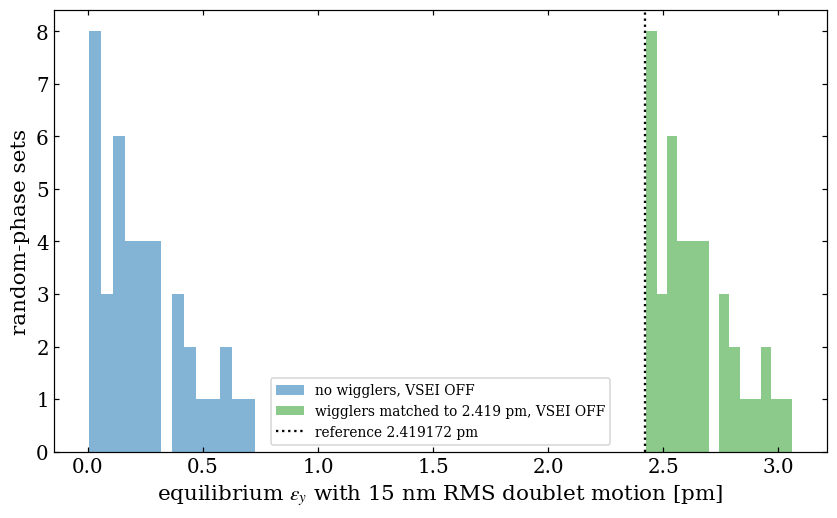

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4.6), layout='constrained')
for state, color, label in (('off', 'tab:blue', 'no wigglers, VSEI OFF'), ('wig_off', 'tab:green', 'wigglers matched to 2.419 pm, VSEI OFF')):
    frame = per_seed if state == 'off' else per_seed_w
    ax.hist(frame[frame.state == state].eps_y_pm, bins=14, alpha=0.55, color=color, label=label)
ax.axvline(REF_PM, color='k', ls=':', label='reference 2.419172 pm')
ax.set_xlabel(r'equilibrium $\varepsilon_y$ with 15 nm RMS doublet motion [pm]'); ax.set_ylabel('random-phase sets'); ax.legend(fontsize=9)
fig.savefig(FIGURES/'emittance_distribution_with_wigglers.png'); plt.show()